PLANETARY DEFENSE ANALYSIS - REGRESSION

In [8]:
#Required Libraries                                                                                                                                                                                                                                     
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
df = pd.read_csv('pha_dataset.csv')

C:\Users\Aishwarya\AppData\Local\Temp\ipykernel_24852\994728929.py:1: DtypeWarning: Columns (3: pdes, 4: name, 5: prefix) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('pha_dataset.csv')


In [10]:
df.shape

(958524, 45)

In [11]:
df.head()

,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,...,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,...,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,...,3.469400e-06,6.272400e-06,9.128200e-06,8.859100e-06,4.961300e-09,4.653600e-10,4.078700e-05,3.680700e-06,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,...,3.223100e-06,1.664600e-05,1.772100e-05,8.110400e-06,4.363900e-09,4.413400e-10,3.528800e-05,3.107200e-06,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,...,2.170600e-07,3.880800e-07,1.789300e-07,1.206800e-06,1.648600e-09,2.612500e-10,4.103700e-06,1.274900e-06,MBA,0.39980
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90,106.699,...,2.740800e-06,2.894900e-05,2.984200e-05,8.303800e-06,4.729000e-09,5.522700e-10,3.474300e-05,3.490500e-06,MBA,0.52191


In [12]:
#Dropping unnecessary columns
df =df.drop(columns=['id','spkid','pdes', 'full_name','name','prefix','equinox','orbit_id']) # Identifiers

In [13]:
df.isnull().sum()

neo                    4
pha                19921
H                   6263
diameter          822315
albedo            823421
diameter_sigma    822443
epoch                  0
epoch_mjd              0
epoch_cal              0
e                      0
a                      0
q                      0
i                      0
om                     0
w                      0
ma                     1
ad                     4
n                      0
tp                     0
tp_cal                 0
per                    4
per_y                  1
moid               19921
moid_ld              127
sigma_e            19922
sigma_a            19922
sigma_q            19922
sigma_i            19922
sigma_om           19922
sigma_w            19922
sigma_ma           19922
sigma_ad           19926
sigma_n            19922
sigma_tp           19922
sigma_per          19926
class                  0
rms                    2
dtype: int64

In [14]:
df = df.dropna(subset=["diameter"]).copy() # Dropping rows with missing diameter values

In [15]:
df.shape

(136209, 37)

In [16]:
df.isnull().sum()

neo                  0
pha                  0
H                 4164
diameter             0
albedo            1109
diameter_sigma     128
epoch                0
epoch_mjd            0
epoch_cal            0
e                    0
a                    0
q                    0
i                    0
om                   0
w                    0
ma                   0
ad                   0
n                    0
tp                   0
tp_cal               0
per                  0
per_y                0
moid                 0
moid_ld              0
sigma_e              0
sigma_a              0
sigma_q              0
sigma_i              0
sigma_om             0
sigma_w              0
sigma_ma             0
sigma_ad             0
sigma_n              0
sigma_tp             0
sigma_per            0
class                0
rms                  0
dtype: int64

In [17]:
df.drop(columns=['diameter_sigma'], inplace=True)

In [18]:
df = df.drop(columns=['sigma_e','sigma_a','sigma_q','sigma_i','sigma_om','sigma_w','sigma_ma','sigma_ad','sigma_n','sigma_tp','sigma_per']) # sigma columns

In [19]:
#Handling null
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')

cols = ['H', 'albedo']
df[cols] = imputer.fit_transform(df[cols])

In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
df.describe()

,H,diameter,albedo,epoch,epoch_mjd,epoch_cal,e,a,q,i,...,ma,ad,n,tp,tp_cal,per,per_y,moid,moid_ld,rms
count,136209.000000,136209.000000,136209.000000,1.362090e+05,136209.000000,1.362090e+05,136209.000000,136209.000000,136209.000000,136209.000000,...,136209.000000,136209.000000,136209.000000,1.362090e+05,1.362090e+05,1.362090e+05,136209.000000,136209.000000,136209.000000,136209.000000
mean,15.134388,5.506429,0.130205,2.458882e+06,58881.928375,2.019732e+07,0.145660,2.819158,2.406130,10.295360,...,184.529202,3.232187,0.219086,2.458901e+06,2.019703e+07,1.787231e+03,4.893173,1.423858,554.122719,0.544153
std,1.366614,9.425164,0.109971,6.484261e+02,648.426065,1.763384e+04,0.077464,1.495980,0.516931,6.812632,...,105.632553,2.839820,0.056912,8.313782e+02,2.299375e+04,8.965840e+03,24.547132,0.513029,199.655301,0.073617
min,3.000000,0.002500,0.001000,2.452464e+06,52464.000000,2.002071e+07,0.000060,0.626210,0.081820,0.022056,...,0.005112,0.999954,0.000135,2.425254e+06,1.928011e+07,1.809999e+02,0.495551,0.000027,0.010335,0.054414
25%,14.400000,2.780000,0.053000,2.459000e+06,59000.000000,2.020053e+07,0.089878,2.542856,2.072478,5.088142,...,91.647097,2.871056,0.181012,2.458571e+06,2.019033e+07,1.481089e+03,4.055000,1.086220,422.724237,0.508920
50%,15.200000,3.972000,0.079000,2.459000e+06,59000.000000,2.020053e+07,0.138919,2.754950,2.368605,9.335690,...,188.275290,3.173515,0.215543,2.459007e+06,2.020061e+07,1.670202e+03,4.572764,1.389580,540.782849,0.544180
75%,16.000000,5.765000,0.188000,2.459000e+06,59000.000000,2.020053e+07,0.191174,3.095029,2.688275,13.670331,...,277.821001,3.472570,0.243064,2.459408e+06,2.021071e+07,1.988820e+03,5.445092,1.702400,662.523008,0.579260
max,29.900000,939.400000,1.000000,2.459000e+06,59000.000000,2.020053e+07,0.983789,376.133297,40.318477,170.334595,...,391.682098,746.169105,1.988951,2.465757e+06,2.038113e+07,2.664472e+06,7294.925719,39.360300,15317.847951,7.725100


In [22]:
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
df[num_cols].skew()

H             -0.702615
diameter      25.852418
albedo         1.696635
epoch         -5.317796
epoch_mjd     -5.317796
epoch_cal     -5.315703
e              1.407371
a            174.781076
q              7.314837
i              1.659299
om             0.185611
w             -0.027659
ma            -0.069455
ad           199.089250
n              6.026977
tp            -3.168572
tp_cal        -3.099067
per          249.879621
per_y        249.879621
moid           7.601012
moid_ld        7.601012
rms            8.741995
dtype: float64

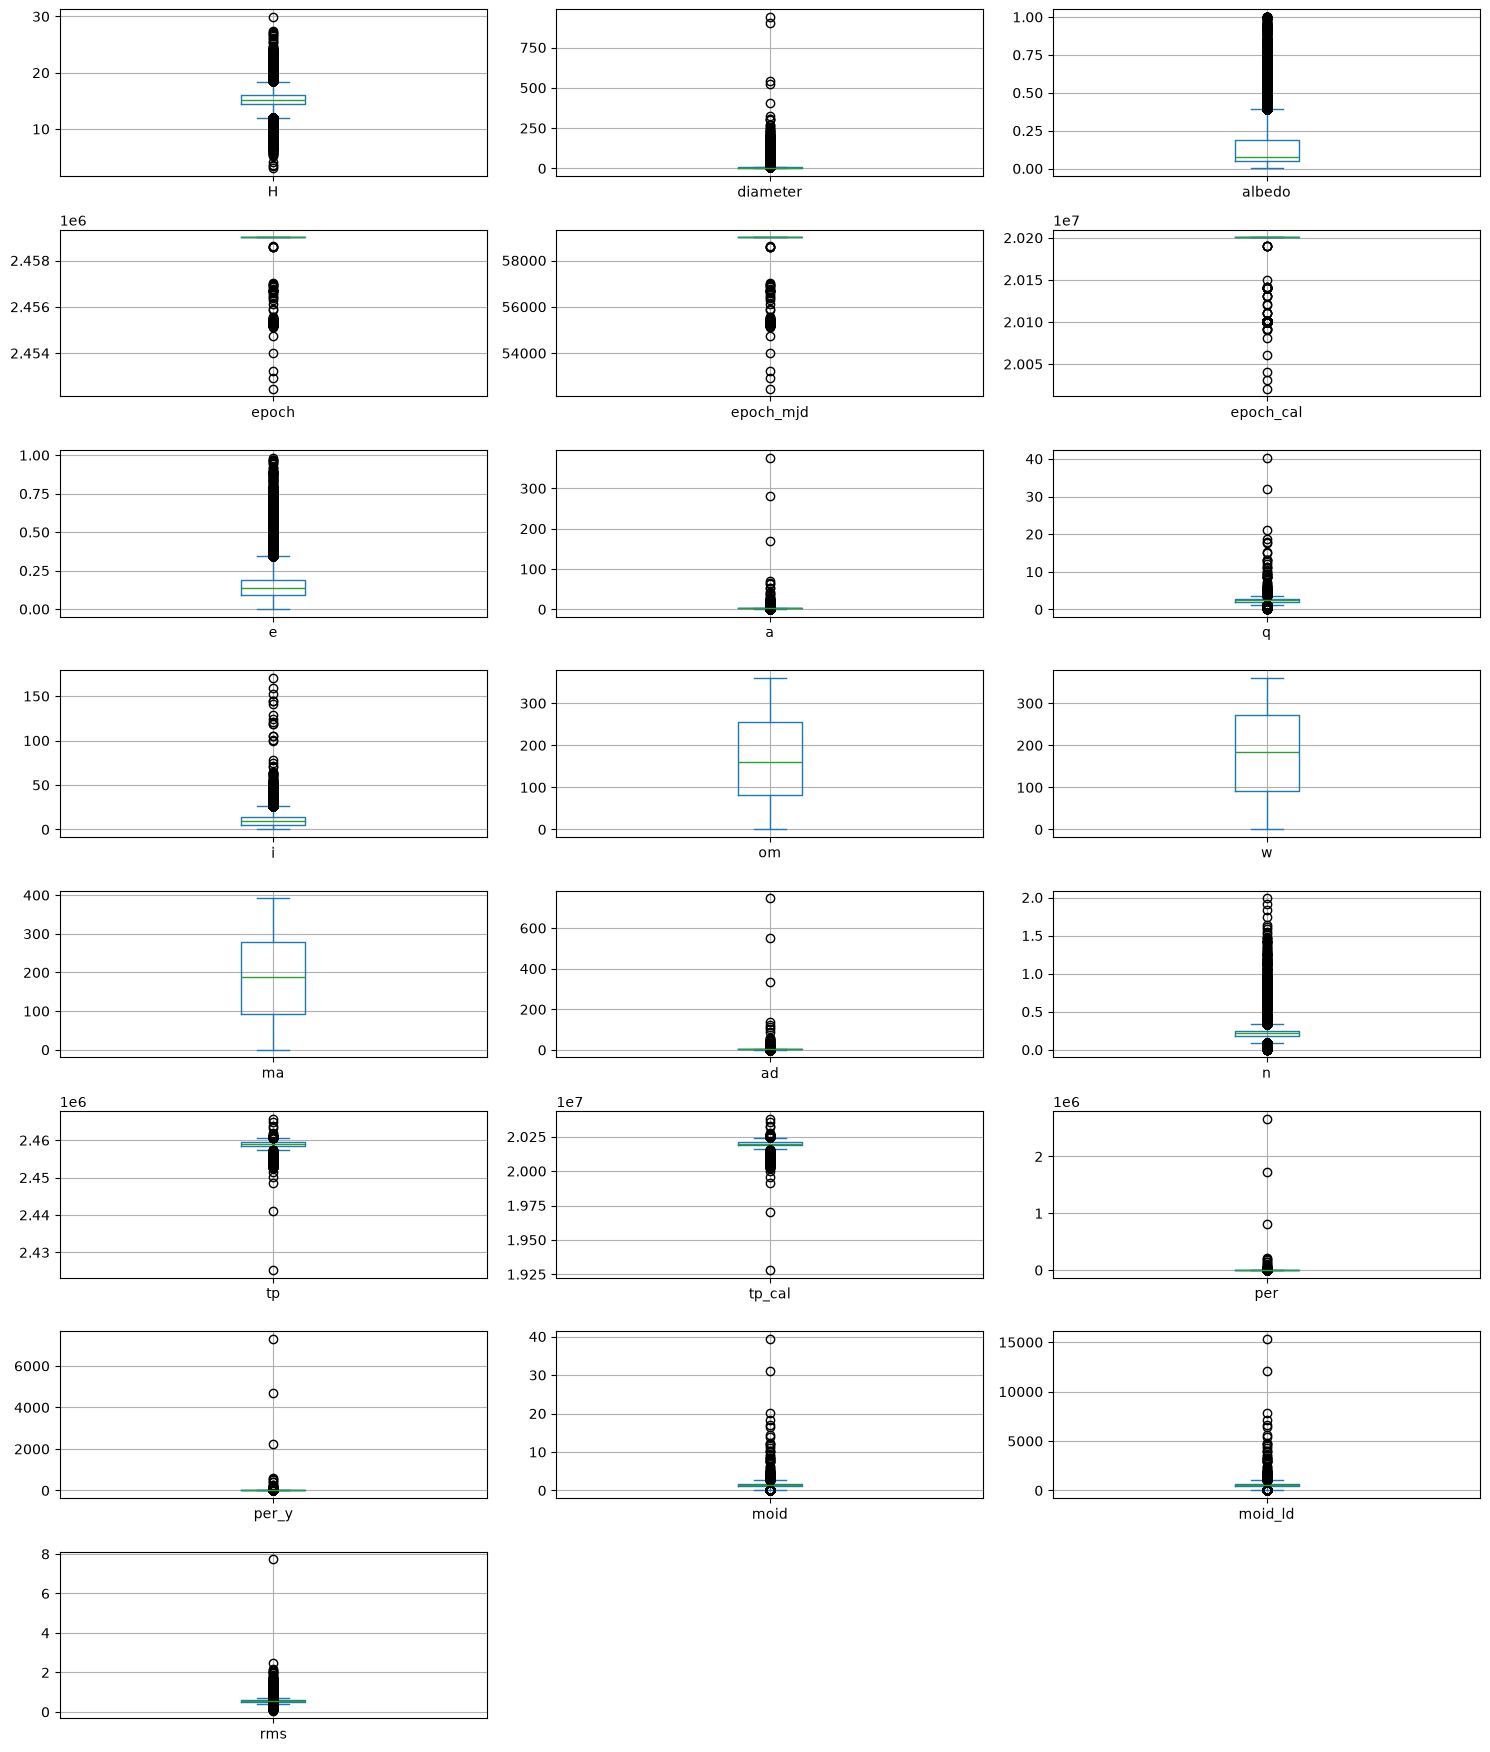

In [23]:
#Outlier detection using boxplots
import matplotlib.pyplot as plt
x = df[num_cols]
x.plot(kind="box",subplots=True,layout=(11,3),figsize=(15, 24),grid=True)
plt.tight_layout()
plt.show()

In [24]:
#IQR method for outlier detection and capping
for col in num_cols:

    Q1 = df[col].quantile(0.25)  # 25th percentile
    Q3 = df[col].quantile(0.75)  # 75th percentile
    IQR = Q3 - Q1  # Interquartile range

    # Define lower and upper bound
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Cap values at lower and upper bound
    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])

In [25]:
df[num_cols].skew()

H           -0.332029
diameter     0.958134
albedo       1.157281
epoch        0.000000
epoch_mjd    0.000000
epoch_cal    0.000000
e            0.436496
a            0.310997
q            0.261984
i            0.825508
om           0.185611
w           -0.027659
ma          -0.069455
ad           0.319273
n            0.166937
tp          -0.566134
tp_cal      -0.348643
per          0.383994
per_y        0.383994
moid         0.263419
moid_ld      0.263419
rms         -0.057789
dtype: float64

In [26]:
#Encoding categorical variables
cat_cols = ['pha','neo', 'class']
df = pd.get_dummies(df,columns=cat_cols,dtype=int)

In [27]:
#Splitting the dataset into features and target variable
X = df.drop(columns=['diameter'])
y = df['diameter']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42)

In [28]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [29]:
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

In [30]:
#Feature selection using random forest regressor
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [31]:
feature_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

In [32]:
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False).reset_index(drop=True)
feature_importance_df

,Feature,Importance
0,H,6.434804e-01
1,albedo,2.251681e-01
2,n,6.447020e-02
3,per_y,1.237553e-02
4,a,9.662222e-03
5,tp,6.808971e-03
6,tp_cal,5.853293e-03
7,per,5.358044e-03
8,i,3.908968e-03
9,ma,3.294255e-03


In [33]:
top_20_features = feature_importance_df.head(20)['Feature'].tolist()
print(top_20_features)

['H', 'albedo', 'n', 'per_y', 'a', 'tp', 'tp_cal', 'per', 'i', 'ma', 'rms', 'ad', 'w', 'q', 'om', 'e', 'moid', 'moid_ld', 'class_MBA', 'neo_N']


In [34]:
X_train_selected = X_train_scaled[top_20_features]
X_test_selected = X_test_scaled[top_20_features]

MODEL BUILDING

In [35]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)

import mlflow
import mlflow.sklearn
import shap

In [36]:
mlflow.set_tracking_uri("http://localhost:5000")

In [37]:
models = {
    "Linear Regression": {
        "estimator": LinearRegression(),
        "params": {}
    },

    "Random Forest Regressor": {
        "estimator": RandomForestRegressor(
            n_estimators=50,
            max_depth=15,
            min_samples_split=5,
            min_samples_leaf=2,
            max_features=0.7,
            random_state=42,
            n_jobs=1
        ),
        "params": {
            "n_estimators": 50,
            "max_depth": 15,
            "min_samples_split": 5,
            "min_samples_leaf": 2,
            "max_features": 0.7,
            "random_state": 42,
            "n_jobs": 1
        }
    },

    "SVR": {
        "estimator": SVR(
            kernel="rbf",
            C=1.0,
            epsilon=0.1
        ),
        "params": {
            "kernel": "rbf",
            "C": 1.0,
            "epsilon": 0.1
        }
    },

    "XGBoost Regressor": {
        "estimator": XGBRegressor(
            n_estimators=100,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            objective="reg:squarederror",
            n_jobs=1
        ),
        "params": {
            "n_estimators": 100,
            "max_depth": 4,
            "learning_rate": 0.05,
            "subsample": 0.8,
            "colsample_bytree": 0.8,
            "random_state": 42,
            "objective": "reg:squarederror",
            "n_jobs": 1
        }
    }
}

In [38]:
#Create the preprocessing pipelines
pipelines = {}

for model_name, model_info in models.items():

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("regressor", clone(model_info["estimator"]))
    ])

    pipelines[model_name] = pipeline

print("All four regression pipelines created successfully!")

All four regression pipelines created successfully!


In [39]:
#Train and evaluate the models
results = []
fitted_pipelines = {}
run_ids = {}

mlflow.set_experiment("Asteroid_Diameter_Regression")

for model_name, model_info in models.items():

    pipeline = clone(pipelines[model_name])

    with mlflow.start_run(run_name=model_name) as run:

        # Record the run ID for later model registration
        run_ids[model_name] = run.info.run_id

        # 1. Log experiment parameters
        mlflow.log_param("model_name", model_name)
        mlflow.log_param("imputer", "median")
        mlflow.log_param("scaler", "StandardScaler")
        mlflow.log_param("target", "diameter")
        mlflow.log_params(model_info["params"])

        # 2. Fit the complete pipeline
        pipeline.fit(X_train, y_train)

        # Keep the fitted pipeline in memory
        fitted_pipelines[model_name] = pipeline

        # 3. Predict on the untouched test set
        y_pred = pipeline.predict(X_test)

        # 4. Calculate metrics
        metrics = {
            "mae": mean_absolute_error(y_test, y_pred),
            "rmse": np.sqrt(mean_squared_error(y_test, y_pred)),
            "r2": r2_score(y_test, y_pred)
        }

        # 5. Log metrics
        mlflow.log_metrics(metrics)

        # 6. Log the fitted pipeline
        mlflow.sklearn.log_model(
            sk_model=pipeline,
            name="model",
            serialization_format="pickle",
        )

        # 7. Save the results for comparison
        results.append({
            "model": model_name,
            **metrics
        })

        print(f"\n{'=' * 55}")
        print(f"Model: {model_name}")
        print(f"{'=' * 55}")

        for metric, value in metrics.items():
            print(f"{metric}: {value:.4f}")

        print(f"MLflow run completed: {model_name}")

2026/10/17 21:43:32 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html



Model: Linear Regression
mae: 0.6742
rmse: 0.8821
r2: 0.8694
MLflow run completed: Linear Regression
🏃 View run Linear Regression at: http://localhost:5000/#/experiments/2/runs/15048cea97d14f59a0179939b9ac9c39
🧪 View experiment at: http://localhost:5000/#/experiments/2


2026/10/17 21:46:06 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html



Model: Random Forest Regressor
mae: 0.2792
rmse: 0.4272
r2: 0.9694
MLflow run completed: Random Forest Regressor
🏃 View run Random Forest Regressor at: http://localhost:5000/#/experiments/2/runs/a65fa92279f345cea501e9880f6719bc
🧪 View experiment at: http://localhost:5000/#/experiments/2


2026/10/17 22:14:14 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html



Model: SVR
mae: 0.3478
rmse: 0.5190
r2: 0.9548
MLflow run completed: SVR
🏃 View run SVR at: http://localhost:5000/#/experiments/2/runs/8288578b6d1b489fbe2e717041b2b6d5
🧪 View experiment at: http://localhost:5000/#/experiments/2


2026/10/17 22:14:42 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html



Model: XGBoost Regressor
mae: 0.3531
rmse: 0.4905
r2: 0.9596
MLflow run completed: XGBoost Regressor
🏃 View run XGBoost Regressor at: http://localhost:5000/#/experiments/2/runs/88cd3813a7ba45d68904c099e9786566
🧪 View experiment at: http://localhost:5000/#/experiments/2


In [40]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="rmse",
    ascending=True
).reset_index(drop=True)

print(results_df)

                     model       mae      rmse        r2
0  Random Forest Regressor  0.279249  0.427231  0.969359
1        XGBoost Regressor  0.353116  0.490470  0.959617
2                      SVR  0.347817  0.519038  0.954775
3        Linear Regression  0.674195  0.882115  0.869374


SHAP

In [41]:
best_model_name = results_df.iloc[0]["model"]

best_model = fitted_pipelines[best_model_name]

print("Selected model:", best_model_name)

Selected model: Random Forest Regressor


In [42]:
X_shap = X_test.sample(
    n=min(200, len(X_test)),
    random_state=42
)

# Apply the fitted preprocessing transformations
X_shap_transformed = best_model.named_steps["imputer"].transform(
    X_shap
)

X_shap_transformed = best_model.named_steps["scaler"].transform(
    X_shap_transformed
)

feature_names = X_train.columns.tolist()

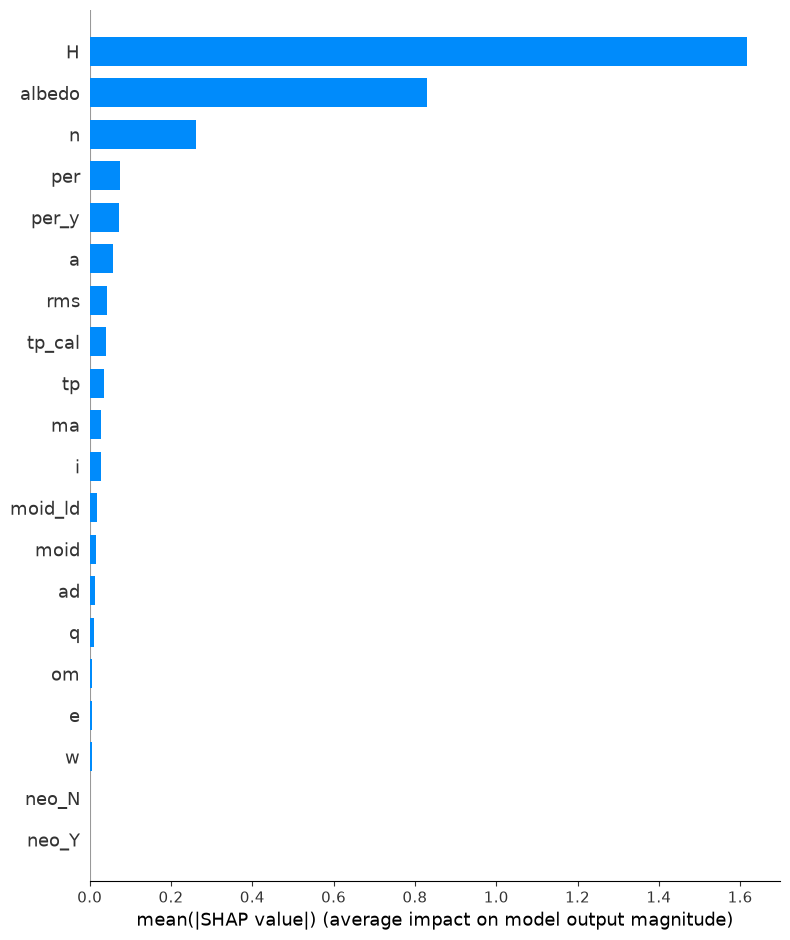

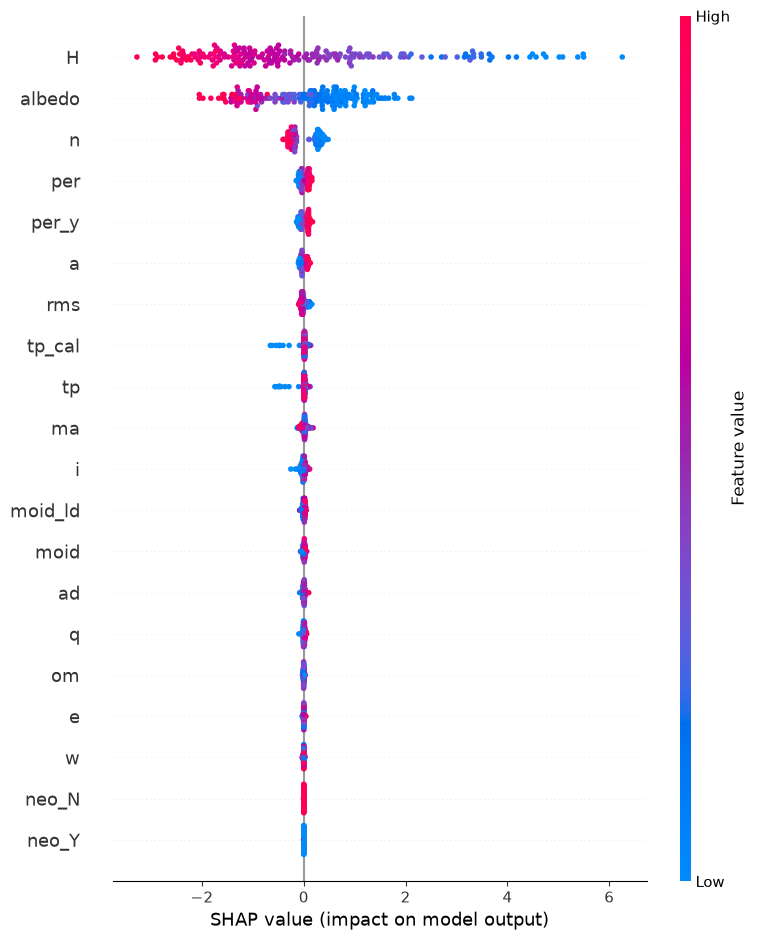

In [43]:
regressor = best_model.named_steps["regressor"]
explainer = shap.TreeExplainer(regressor)
shap_values = explainer.shap_values(
        X_shap_transformed
    )

# Global feature importance
shap.summary_plot(shap_values,
        X_shap_transformed,
        feature_names=feature_names,
        plot_type="bar"
    )
# Direction and distribution of feature effects
shap.summary_plot(
        shap_values,
        X_shap_transformed,
        feature_names=feature_names
    )

In [44]:
#Register the best model in MLflow Model Registry
model_name = "Asteroid_Diameter_Regressor"

selected_run_id = run_ids[best_model_name]

registered_model = mlflow.register_model(
    model_uri=f"runs:/{selected_run_id}/model",
    name=model_name
)

print("Registered model:", registered_model.name)
print("Model version:", registered_model.version)

Successfully registered model 'Asteroid_Diameter_Regressor'.
2026/10/22 07:52:08 WARNING mlflow.tracking._model_registry.fluent: Run with id a65fa92279f345cea501e9880f6719bc has no artifacts at artifact path 'model', registering model based on models:/m-d9a66248716a4348ad3c19ae8f526414 instead
2026/10/22 07:52:08 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: Asteroid_Diameter_Regressor, version 1
Created version '1' of model 'Asteroid_Diameter_Regressor'.


Registered model: Asteroid_Diameter_Regressor
Model version: 1


In [45]:
registered_pipeline = mlflow.sklearn.load_model(
    f"models:/{model_name}/{registered_model.version}"
)

print("Registered model loaded successfully!")

Registered model loaded successfully!


In [46]:
# JSON 
import json
feature_config = []

for column in X_train.columns:

    median_value = pd.to_numeric(
        X_train[column],
        errors="coerce"
    ).median()

    if pd.isna(median_value):
        median_value = 0.0

    feature_config.append({
        "name": str(column),
        "default": float(median_value)
    })

with open("feature_config.json", "w") as file:
    json.dump(feature_config, file, indent=4)

print("Feature configuration saved!")

Feature configuration saved!
